# Examine Features
This jupyter notebook assumes you have already processed the images found in ``data/sitters/`` into the ``features.pkl`` file.

In [9]:
import pandas as pd
import numpy as np
import os

features = pd.read_pickle(r'../results/features.pkl')
features.head()

# features.pkl was extracted before some faces were removed by hand from data/sitters/
# (duplicates, low quality, mismatched sitters). results/face_list_paper.csv lists the faces
# that remained and were used in the paper; keep only those rows.
face_list = pd.read_csv('../results/face_list_paper.csv', dtype=str)
keep = pd.MultiIndex.from_frame(face_list[['folder', 'filename']])
features2 = features[pd.MultiIndex.from_frame(features[['folder', 'filename']]).isin(keep)].copy()

print("Original rows:", len(features))
print("Cleaned rows:", len(features2))
print("Removed rows:", len(features) - len(features2))
features = features2



Original rows: 1884
Cleaned rows: 1859
Removed rows: 25


In [10]:
len(features2['folder'].unique())

1725

In [11]:
# If we only want to evaluate the sitters with more than one face image
filtered_df = features2[features2['folder'].duplicated(keep=False)]

# Sitter 111078 had a photoshoot, with multiple images of the sitter from the same session, this might bias the results.
filtered_df2 = filtered_df[filtered_df['folder'] != '111078']
filtered_df2.head()

filtered_csv = filtered_df.copy()
filtered_csv2 = filtered_df2.copy()

filtered_csv.drop(columns='feature', inplace=True)
filtered_csv2.drop(columns='feature', inplace=True)

filtered_csv.to_csv('../results/face_list_multi.csv', index=False)
filtered_csv2.to_csv('../results/face_list_multi_excl_111078.csv', index=False)

In [12]:
########### Get the metrics  ###########
"""
This snippet stacks the embeddings (the feature vectors in features.pkl), normalizes the and uses the cosine_similarity metric to calculate the angle between the vectors to evaluate the similarity.
This is then used to calculate the False Positive Rate (FPR), True Positive Rate (TPR) for several thresholds.
"""

from sklearn.metrics.pairwise import cosine_similarity
import numpy as np
from sklearn.preprocessing import normalize

df = filtered_df

embeddings = np.stack(df['feature'].values).squeeze(1)
norm_embeddings = normalize(embeddings, norm='l2')
similarity_matrix = cosine_similarity(embeddings)  # shape (N, N)
print(similarity_matrix.shape)

identities = df['folder'].values
identity_matrix = np.equal.outer(identities, identities).astype(int)  # (N, N)

i, j = np.triu_indices_from(similarity_matrix, k=1)

similarities = similarity_matrix[i, j]        # similarity scores
labels = identity_matrix[i, j]

from sklearn.metrics import roc_curve, auc

fpr, tpr, thresholds = roc_curve(1-labels,1-similarities)
print(fpr)
print(tpr)
print(thresholds)
roc_auc = auc(fpr, tpr)
print(1-similarities)

(205, 205)
[0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.00309598 0.00309598 0.00619195
 0.00619195 0.00928793 0.00928793 0.00928793 0.00928793 0.0123839
 0.0123839  0.0123839  0.0123839  0.0123839  0.0123839  0.0123839
 0.0123839  0.0123839  0.0123839  0.0123839  0.0123839  0.0123839
 0.0123839  0.0123839  0.0123839  0.0123839  0.0123839  0.0123839
 0.0123839  0.0123839  0.0123839  0.01547988 0.01547988 0.01547988
 0.01547988 0.01857585 0.01857585 0.01857585 0.01857585 0.01857585
 0.01857585 0.01857585 0.01857585 0.01857585 0.01857585 0.01857585
 0.01857585 0.02167183 0.02167183 0.02167183 0.02167183 0.0247678
 0.0247678  0.02786378 0.02786378 0.03095975 0.03095975 0.03405573
 0.03405573 0.03405573 0.03405573 0.0371517  0.0371517  0.04024768
 0.04024768 0.0402476

In [13]:
########### Leave One Out ###########
"""
This snippet calculates the leave one out validation technique
We stack the embeddings (the feature vectors in features.pkl) and use the cosine_similarity metric to calculate the angle between the vectors to evaluate the similarity.
This is then used to calculate the False Positive Rate (FPR), True Positive Rate (TPR) for several thresholds.
"""

from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import roc_curve


def leave_one_out_from_df(df: pd.DataFrame):
    genuine_scores = []
    imposter_scores = []

    for idx, row in df.iterrows():
        probe_id = row["folder"]
        probe_feat = row["feature"].reshape(1, -1)

        # Genuine comparisons (same identity, exclude self)
        genuine_feats = df[(df["folder"] == probe_id) & (df.index != idx)]["feature"]
        if len(genuine_feats) > 0:
            g_scores = cosine_similarity(probe_feat, np.vstack(genuine_feats))[0]
            genuine_scores.extend(g_scores)

        # Imposter comparisons (different identity)
        imposter_feats = df[df["folder"] != probe_id]["feature"]
        if len(imposter_feats) > 0:
            i_scores = cosine_similarity(probe_feat, np.vstack(imposter_feats))[0]
            imposter_scores.extend(i_scores)

    return np.array(genuine_scores), np.array(imposter_scores)


# Calculate
genuine, imposter = leave_one_out_from_df(df)

# Compute EER
y_true = np.concatenate([np.ones_like(genuine), np.zeros_like(imposter)])
y_scores = np.concatenate([genuine, imposter])
fpr, tpr, thresholds = roc_curve(y_true, y_scores)
eer_idx = np.nanargmin(np.abs(fpr - (1 - tpr)))
eer = fpr[eer_idx]
print("EER:", eer)

print("FPR:", fpr)
print("TPR:", tpr)
print("Thresholds:", thresholds)


EER: 0.1315393209306844
FPR: [0.         0.         0.         ... 0.98659348 0.98664206 1.        ]
TPR: [0.         0.00309598 0.00619195 ... 1.         1.         1.        ]
Thresholds: [        inf  0.9159976   0.8991011  ... -0.09266739 -0.09271369
 -0.23339413]


EER threshold: 0.17756931
Genuine range: 0.02667049 0.9159976
Impostor range: -0.23339413 0.5518921


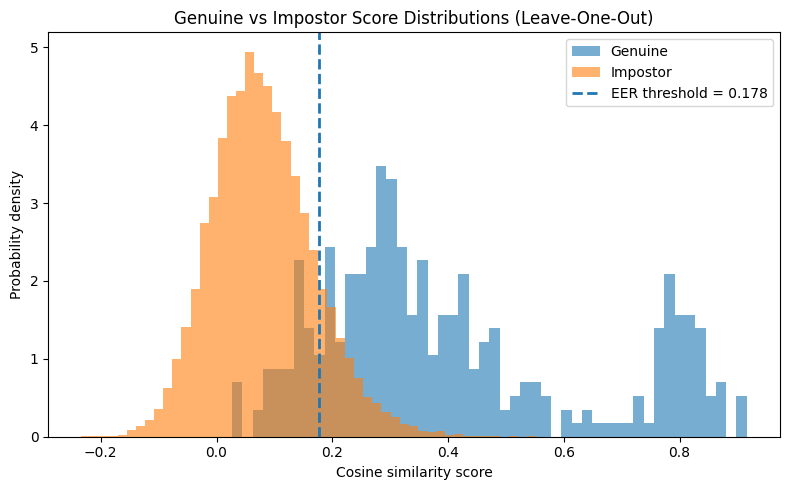

In [15]:
eer_threshold = thresholds[eer_idx]
print("EER threshold:", eer_threshold)

print("Genuine range:", genuine.min(), genuine.max())
print("Impostor range:", imposter.min(), imposter.max())

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

# Genuine scores
plt.hist(
    genuine,
    bins=50,
    density=True,
    alpha=0.6,
    label="Genuine",
)

# Impostor scores
plt.hist(
    imposter,
    bins=50,
    density=True,
    alpha=0.6,
    label="Impostor",
)

# EER threshold
plt.axvline(
    eer_threshold,
    linestyle="--",
    linewidth=2,
    label=f"EER threshold = {eer_threshold:.3f}",
)

plt.xlabel("Cosine similarity score")
plt.ylabel("Probability density")
plt.title("Genuine vs Impostor Score Distributions (Leave-One-Out)")
plt.legend()
plt.grid(False)
plt.tight_layout()
plt.savefig(os.path.join('../figures', f"genuine_vs_impostor_score_distribution.png"))
plt.show()

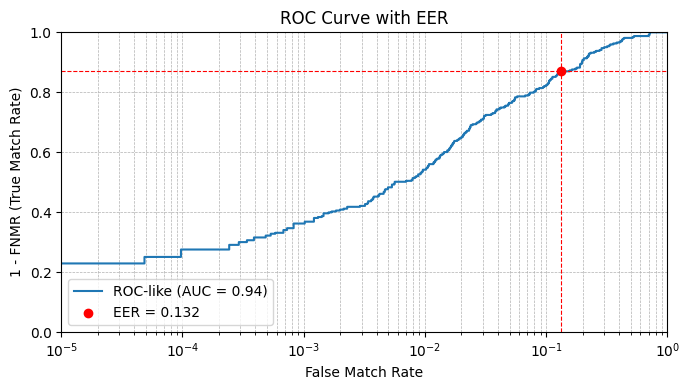

In [16]:
from matplotlib import pyplot as plt

# Compute FNMR (False Non-Match Rate)
fnmr = 1 - tpr
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(7,4))

# Plot FMR (x) vs 1 - FNMR (y), i.e. TPR
plt.plot(fpr, 1 - fnmr, label=f'ROC-like (AUC = {roc_auc:.2f})')

# Plot chance line (random performance)
# plt.plot([1e-6, 1], [0, 1], 'k--', label='Chance')

# Plot EER point
plt.scatter(fpr[eer_idx], 1 - fnmr[eer_idx],
            c='red', zorder=5, label=f'EER = {eer:.3f}')
plt.axvline(fpr[eer_idx], color='red', linestyle='--', linewidth=0.8)
plt.axhline(1 - fnmr[eer_idx], color='red', linestyle='--', linewidth=0.8)

# Axis settings
plt.xscale('log')
plt.xlim([1e-5, 1])   # log scale needs strictly positive values
plt.ylim([0, 1])

plt.xlabel('False Match Rate')
plt.ylabel('1 - FNMR (True Match Rate)')
plt.title('ROC Curve with EER')
plt.legend()
plt.grid(True, which="both", ls="--", linewidth=0.5)
plt.tight_layout()
plt.savefig(os.path.join('../figures', f"log_roc_curve_with_EER.png"))
plt.show()

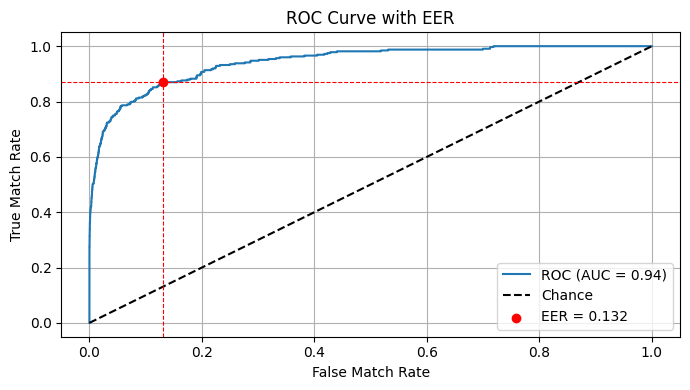

In [17]:
plt.figure(figsize=(7, 4))
plt.plot(fpr, tpr, label=f'ROC (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--', label='Chance')

# Plot EER point
plt.scatter(fpr[eer_idx], tpr[eer_idx], c='red', zorder=5, label=f'EER = {eer:.3f}')
plt.axvline(fpr[eer_idx], color='red', linestyle='--', linewidth=0.8)
plt.axhline(tpr[eer_idx], color='red', linestyle='--', linewidth=0.8)

plt.xlabel('False Match Rate')
plt.ylabel('True Match Rate')
plt.title('ROC Curve with EER')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join('../figures', f"roc_curve_with_EER.png"))
plt.show()

In [18]:
# Target FARs (false accept rates)
target_fars = [0.00001, 0.00005, 0.0001, 0.0005, 0.001, 0.005, 0.01, 0.05, 0.1]   # 0.01%, 0.1%, 1%, 10%

results = []
for target_fpr in target_fars:
    idxs = np.where(fpr <= target_fpr)[0]
    if len(idxs) > 0:
        best_idx = idxs[np.argmax(tpr[idxs])]
        results.append({
            "FAR": target_fpr,
            "#False Matches": target_fpr*194,
            "TAR": tpr[best_idx],
            "FNMR": 1 - tpr[best_idx],
            "Threshold": thresholds[best_idx]
        })
    else:
        results.append({
            "FAR": target_fpr,
            "TAR": None,
            "Threshold": None
        })

df_results = pd.DataFrame(results)
print(df_results)

       FAR  #False Matches       TAR      FNMR  Threshold
0  0.00001         0.00194  0.229102  0.770898   0.555321
1  0.00005         0.00970  0.250774  0.749226   0.520612
2  0.00010         0.01940  0.275542  0.724458   0.486973
3  0.00050         0.09700  0.321981  0.678019   0.443408
4  0.00100         0.19400  0.362229  0.637771   0.418136
5  0.00500         0.97000  0.482972  0.517028   0.345868
6  0.01000         1.94000  0.541796  0.458204   0.315634
7  0.05000         9.70000  0.764706  0.235294   0.232911
8  0.10000        19.40000  0.823529  0.176471   0.194547


In [19]:
print(tpr)
print(fpr)

# Target FAR
target_fpr = 0.1

# Find all thresholds where FPR <= 0.001
indices = np.where(fpr <= target_fpr)[0]

# Choose the one with highest TPR (best trade-off)
best_idx = indices[np.argmax(tpr[indices])]

# Threshold at FAR = 0.1%
threshold_at_far = thresholds[best_idx]
preds = (similarities >= threshold_at_far).astype(int)

from sklearn.metrics import accuracy_score

acc = accuracy_score(labels, preds)
print(f'Accuracy at FAR = {target_fpr*100:.2f}%: {acc*100:.2f}%')

[0.         0.00309598 0.00619195 ... 1.         1.         1.        ]
[0.         0.         0.         ... 0.98659348 0.98664206 1.        ]
Accuracy at FAR = 10.00%: 89.95%


# T-SNE Evaluation
T-SNE can be used to find clusters in high dimensional data. This is purely a visualization tool.

Text(0.5, 1.0, 't-SNE')

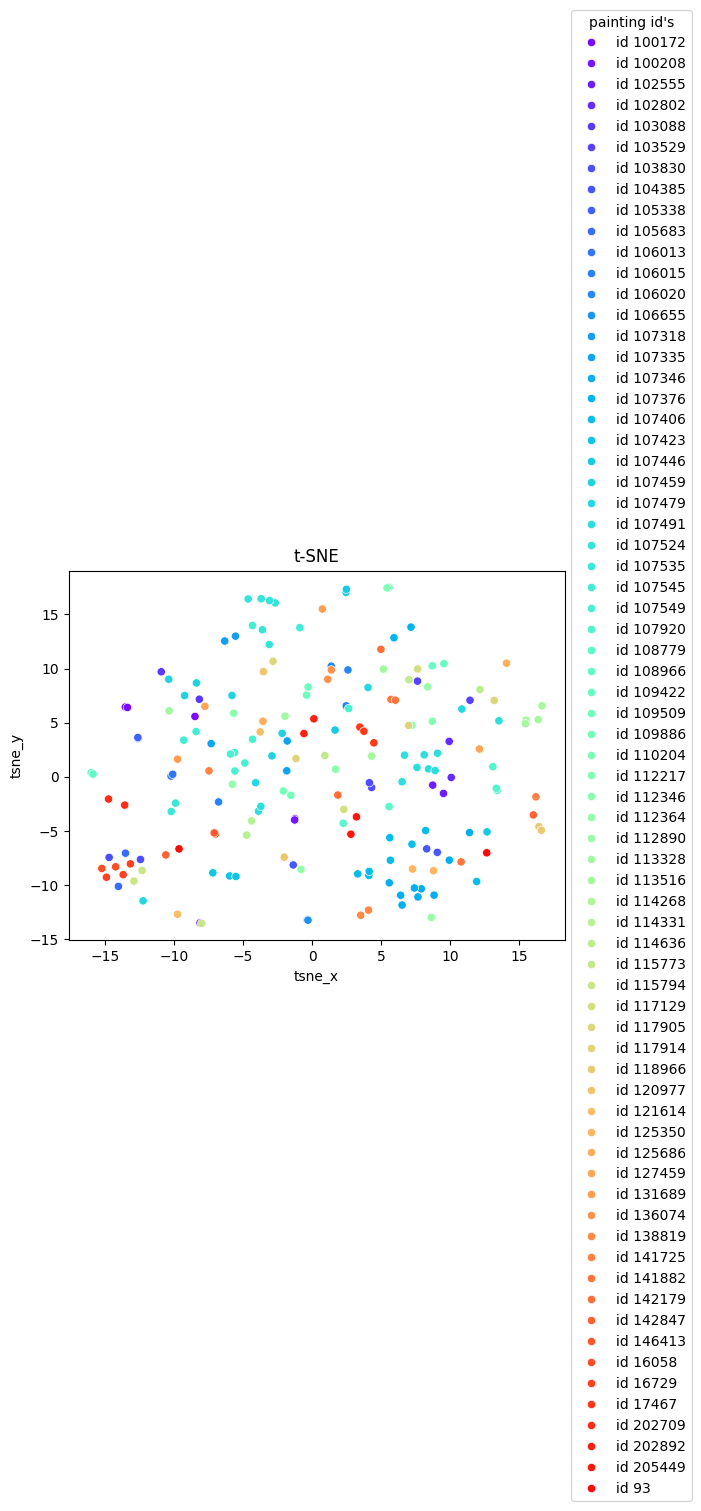

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import TSNE

df = filtered_df2 # Only the multi-face sitters

feature_emb = np.stack(df['feature'].values).squeeze(1)
# print(feature_emb.shape, type(feature_emb))
# print(feature_emb)


metrics = TSNE(n_components=2).fit_transform(norm_embeddings)
sorting = np.argsort(df['folder'].values)
new_labels = np.array([f'id {label}' for label in df['folder'].values.astype(int)])[sorting]
tsnex = np.array(metrics[:, 0])[sorting]
tsney = np.array(metrics[:, 1])[sorting]

df = pd.DataFrame([new_labels, tsnex, tsney], index=['label', 'tsne_x', 'tsne_y'])

df = df.transpose()
plt.figure()
g = sns.scatterplot(x='tsne_x', y='tsne_y', hue='label', palette="rainbow", data=df)
g.legend(loc='center left', bbox_to_anchor=(1, 0.5), title="painting id's")
plt.title(f't-SNE')

# Similarity Matrix
Shows the faces that are classified the same for a certain threshold. The identities on the diagonal are the same.

<Axes: >

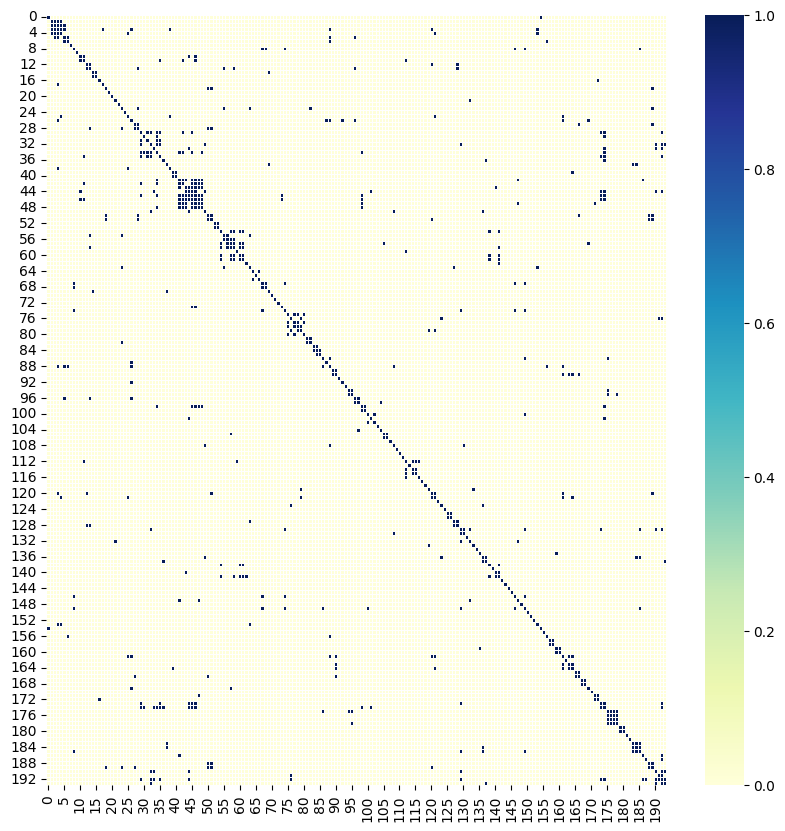

In [21]:
from sklearn.metrics.pairwise import cosine_similarity

df = filtered_df2

identities = df['folder'].values
embeddings = np.stack(df['feature'].values).squeeze(1)
similarity_matrix = cosine_similarity(embeddings)
thresh = 0.32
similarity_matrix[similarity_matrix <= thresh] = 0
similarity_matrix[similarity_matrix > thresh] = 1
fig, ax = plt.subplots(figsize=(10,10))
sns.heatmap(similarity_matrix, annot=False, cmap='YlGnBu', linewidths=.5, ax=ax)

# Creating folder with similarity pairs above threshold

In [22]:
# Define the threshold
threshold = 0.5

df = filtered_df

embeddings = np.stack(df['feature'].values).squeeze(1)
norm_embeddings = normalize(embeddings, norm='l2')

# Calculate similarity matrix
similarity_matrix = cosine_similarity(norm_embeddings)
identity_matrix = np.equal.outer(identities, identities).astype(int)
i, j = np.triu_indices_from(similarity_matrix, k=1)
similarities = similarity_matrix[i, j]   # cosine similarity scores
labels = identity_matrix[i, j]          # 1 = same ID, 0 = different

preds = (similarities >= threshold).astype(int)

# Identify which pairs are positive matches and false matches
true_accepts_idx = np.where((preds == 1) & (labels == 1))[0]  # genuine accepted
false_accepts_idx = np.where((preds == 1) & (labels == 0))[0] # impostor accepted
false_reject_idx = np.where((preds == 0) & (labels == 1))[0]  # genuine accepted

i, j = np.triu_indices(len(df), k=1)

import os
from PIL import Image

output_dir = f"pair_examples5_t{threshold}"
os.makedirs(output_dir, exist_ok=True)
os.makedirs(f'{output_dir}/True_Match', exist_ok=True)
os.makedirs(f'{output_dir}/False_Match', exist_ok=True)
os.makedirs(f'{output_dir}/False_Reject', exist_ok=True)

def save_pair(idx_list, label):
    """Save up to max_pairs image pairs for a given category (label string)."""
    for n, k in enumerate(idx_list):
        img1_file = df.iloc[i[k]]['filename']
        img1_folder = df.iloc[i[k]]['folder']

        img2_file = df.iloc[j[k]]['filename']
        img2_folder = df.iloc[j[k]]['folder']

        try:
            img1 = Image.open(f'../data/sitters/{img1_folder}/{img1_file}.jpg')
            img2 = Image.open(f'../data/sitters/{img2_folder}/{img2_file}.jpg')

            # Concatenate side by side
            w, h = img1.size
            combined = Image.new("RGB", (2*w, h))
            combined.paste(img1, (0, 0))
            combined.paste(img2, (w, 0))

            if label == 'true_accept':
                save_path = os.path.join(output_dir, f"True_Match/id1-{img1_folder}_{img1_file}_id2-{img2_folder}_{img2_file}.jpg")
            elif label == 'false_accept':
                save_path = os.path.join(output_dir, f"False_Match/id1-{img1_folder}_{img1_file}_id2-{img2_folder}_{img2_file}.jpg")
            elif label == 'false_reject':
                save_path = os.path.join(output_dir, f"False_Reject/id1-{img1_folder}_{img1_file}_id2-{img2_folder}_{img2_file}.jpg")
            combined.save(save_path)
        except Exception as e:
            print(f"Skipping pair {img1_file}, {img2_file}: {e}")


save_pair(true_accepts_idx, "true_accept")
save_pair(false_accepts_idx, "false_accept")
save_pair(false_reject_idx, "false_reject")

IndexError: index 194 is out of bounds for axis 0 with size 194